# dmd-operador-global — interpretabilidad del operador final

Operador oficial: **GRU** (3 semillas), DMD exacto autónomo horario + Duan, modos de 1.6 v2 (regla del operador, pausa 8.3), reajustado hasta 2026-06-30 (etapa `cierre`). PCA como secundario. Lee el estado local `mlflow-op/` (sin AWS).

Caveats: el decoder del AE es no lineal (S5): la descomposición por modo usa el jacobiano del decoder en el latente medio (aproximada). En PCA es exacta. Los modos actúan en `log1p(µg/m³)`: son multiplicativos en µg/m³.

In [1]:
import json, pathlib, sys, os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
ROOT = pathlib.Path.cwd()
while not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from operador import run as R, modos as M, evaluacion as V
args = R.parse_args(["--etapa", "cierre", "--state-dir", "mlflow-op", "--local-validated-dir", "validated-op", "--no-download"])
from operador import registro as G
args.config = G.leer_decisiones()["1.6"]["config"]
rec = R.Recursos(args)
cierre = json.loads((rec.out / R.CIERRE_JSON).read_text(encoding="utf-8"))
SEEDS = [0, 1, 2]
CANALES = [f"{s.split()[0][:3]}-{p}" if not s.startswith("Padre") else f"PLC-{p}" for s, p in V.SERIES]
print(cierre["runs"])

{'gru-s0': '9ce446a7e97e4472b3bb8de6045863b0', 'gru-s1': 'c90832b65f1d439f8f9a8929db29afb6', 'gru-s2': 'def91f6759714fac8b6e6ac13edcc1ab', 'pca': '72ef57cbdc41446c86314691987225cc'}


## 1. Espectro con intervalos (bootstrap por bloques de 7 días, B = 200, datos hasta 2026-06)

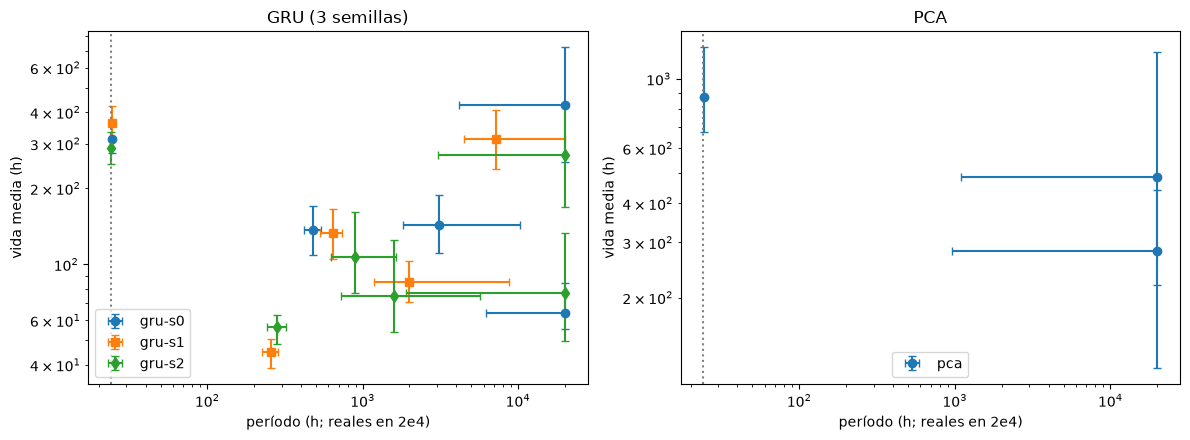

periodo_h  vida_media_h  aparicion  vida_media_h_lo  \
gru-s0 0          inf    428.020315      0.725       253.994450   
       1    24.168714    312.475497      1.000       274.718197   
       2  3096.871303    142.733290      0.435       111.099698   
       3   480.430280    136.182282      0.970       109.117052   
       4          inf     64.118614      0.950        55.335231   
gru-s1 0    24.292528    360.764532      1.000       309.323229   
       1  7206.597183    312.088557      0.365       238.903033   
       2   639.704464    133.199864      0.980       104.557657   
       3  2000.219874     85.258709      0.485        71.073938   
       4   255.859353     44.925076      1.000        38.869556   
gru-s2 0    24.015392    288.474010      0.990       249.219127   
       1          inf    271.339444      0.665       168.557260   
       2   890.670511    107.363576      0.625        76.682039   
       3          inf     76.835797      0.615        49.639682   
       4  1601.076675     75.157332      0.290        53.813700   
       5   280.660978     56.539179      0.995        48.251824   
pca    0    24.290660    875.716951      0.905       674.987487   
       1          inf    486.631309      0.365       219.656971   
       2          inf    281.243340      0.405       119.042184   

          vida_media_h_hi  
gru-s0 0       721.742848  
       1       364.406393  
       2       188.414765  
       3       169.689317  
       4        84.671545  
gru-s1 0       423.674527  
       1       409.170526  
       2       164.876424  
       3       103.340956  
       4        50.517703  
gru-s2 0       332.939968  
       1       425.817504  
       2       160.604366  
       3       132.629033  
       4       125.048339  
       5        62.996049  
pca    0      1260.237876  
       1      1218.518088  
       2       441.206887

In [2]:
def boot(key):
    return pd.read_parquet(rec.artifact(cierre["runs"][key], "bootstrap_modos.parquet"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, keys, title in ((axes[0], [f"gru-s{s}" for s in SEEDS], "GRU (3 semillas)"), (axes[1], ["pca"], "PCA")):
    for k, mk in zip(keys, "osd"):
        b = boot(k)
        per = b["periodo_h"].replace(np.inf, 2e4)
        xe = np.vstack([per - b["periodo_h_lo"].fillna(per).clip(upper=2e4), b["periodo_h_hi"].fillna(per).clip(upper=2e4) - per]).clip(min=0)
        ye = np.vstack([b["vida_media_h"] - b["vida_media_h_lo"], b["vida_media_h_hi"] - b["vida_media_h"]]).clip(min=0)
        ax.errorbar(per, b["vida_media_h"], xerr=xe, yerr=ye, fmt=mk, capsize=3, label=k)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.axvline(24, color="grey", ls=":")
    ax.set_xlabel("período (h; reales en 2e4)"); ax.set_ylabel("vida media (h)"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()
pd.concat({k: boot(k)[["periodo_h", "vida_media_h", "aparicion", "vida_media_h_lo", "vida_media_h_hi"]] for k in cierre["runs"]})

## 2. Formas de modo por estación y contaminante (fase = desfase entre estaciones)

Amplitud y fase de cada modo en la última hora de la ventana decodificada (jacobiano del decoder en el latente medio de ajuste; en PCA, exacto). Desfase en horas = Δfase / 2π × período, relativo a PLC II pm25.

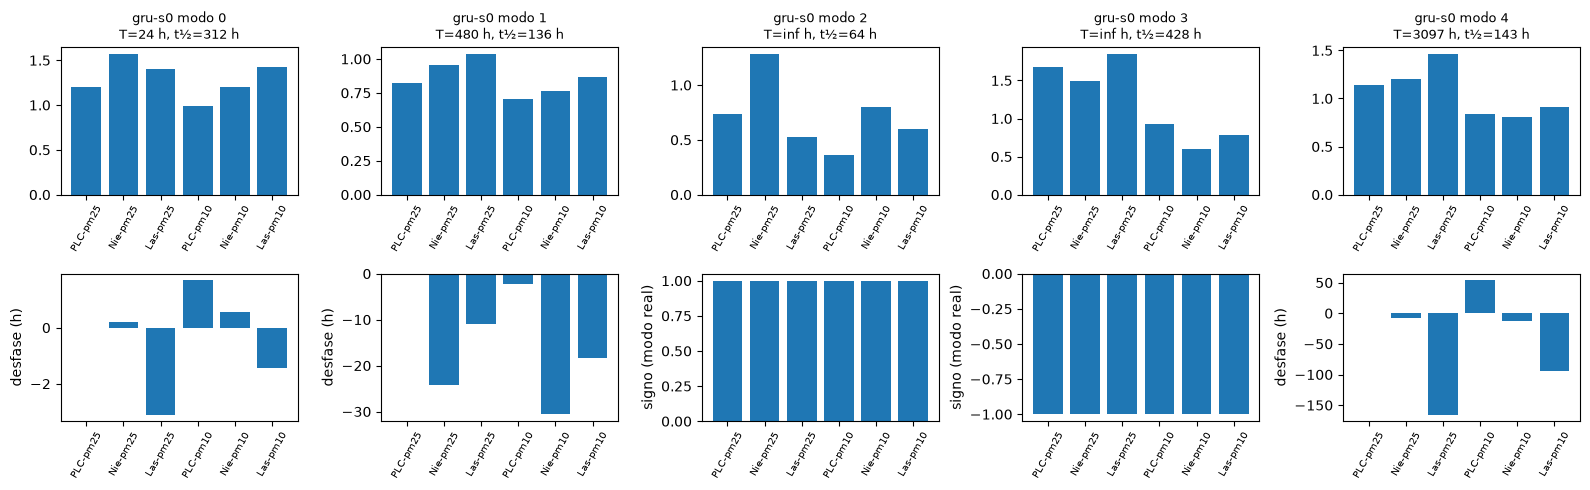

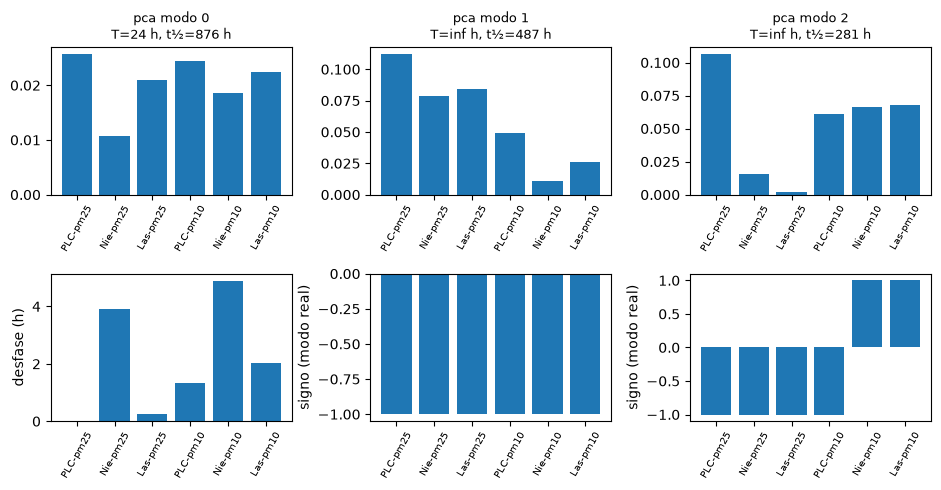

In [3]:
def operador(key):
    return R.cargar_operador(rec, cierre["runs"][key])

def estado(key):
    rep, seed = (key.split("-s")[0], int(key.split("-s")[1])) if "-s" in key else (key, 0)
    return R.estado_cierre(rec, rep, seed)

def jacobiano(est, z0, h=1e-3):
    base = est.decode_log(z0[None])[0]          # [24, 6]
    J = np.zeros((24, 6, len(z0)))
    for i in range(len(z0)):
        dz = np.zeros_like(z0); dz[i] = h
        J[:, :, i] = (est.decode_log((z0 + dz)[None])[0] - base) / h
    return J

def modos_de(op):
    lam, V_ = np.linalg.eig(op.A)
    W = np.linalg.inv(V_)
    keep = [complex(*x) for x in op.meta["modos_conservados"]]
    idx = [int(np.argmin(np.abs(lam - k))) for k in keep]
    return lam[idx], V_[:, idx], W[idx, :]

formas = {}
for key in ["gru-s0", "pca"]:
    est, op = estado(key), operador(key)
    z0 = est.z[est.fit_mask()].mean(axis=0)
    J = jacobiano(est, z0)
    lam, Vk, Wk = modos_de(op)
    U = op.U if op.U is not None else np.eye(est.d)
    shape = np.einsum("hcd,dm->hcm", J, U @ Vk)[-1]   # [6, m] última hora
    formas[key] = (lam, shape, J, Vk, Wk, est, op)
    m = len(lam)
    fig, axes = plt.subplots(2, m, figsize=(3.2 * m, 5), squeeze=False)
    for j in range(m):
        per = M.periodo_h([lam[j]])[0]
        amp, ph = np.abs(shape[:, j]), np.angle(shape[:, j])
        axes[0, j].bar(CANALES, amp); axes[0, j].set_title(f"{key} modo {j}\nT={per:.0f} h, t½={M.vida_media_h([lam[j]])[0]:.0f} h", fontsize=9)
        if np.isfinite(per):
            des = np.angle(np.exp(1j * (ph - ph[0]))) / (2 * np.pi) * per
            axes[1, j].bar(CANALES, des); axes[1, j].set_ylabel("desfase (h)")
        else:
            axes[1, j].bar(CANALES, np.sign(shape[:, j].real)); axes[1, j].set_ylabel("signo (modo real)")
        for a in axes[:, j]:
            a.tick_params(axis="x", rotation=60, labelsize=7)
    plt.tight_layout(); plt.show()

## 3. Descomposición de episodios por modo

Tres episodios de `sel` (máximo `y` en PLC II pm25, Ñielol pm25 y Las Encinas pm10). Aporte de cada modo al promedio de 24 h pronosticado, en `log1p` (jacobiano; exacto en PCA), y pronóstico completo vs real.

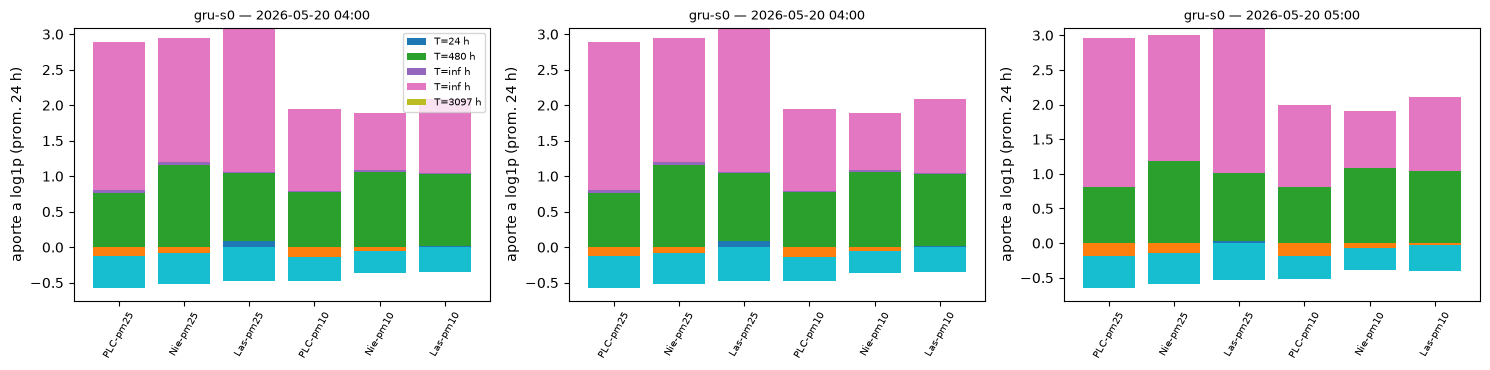

gru-s0 último episodio: pronóstico [ 97.8  71.3  86.1 104.1  76.4  94.3]


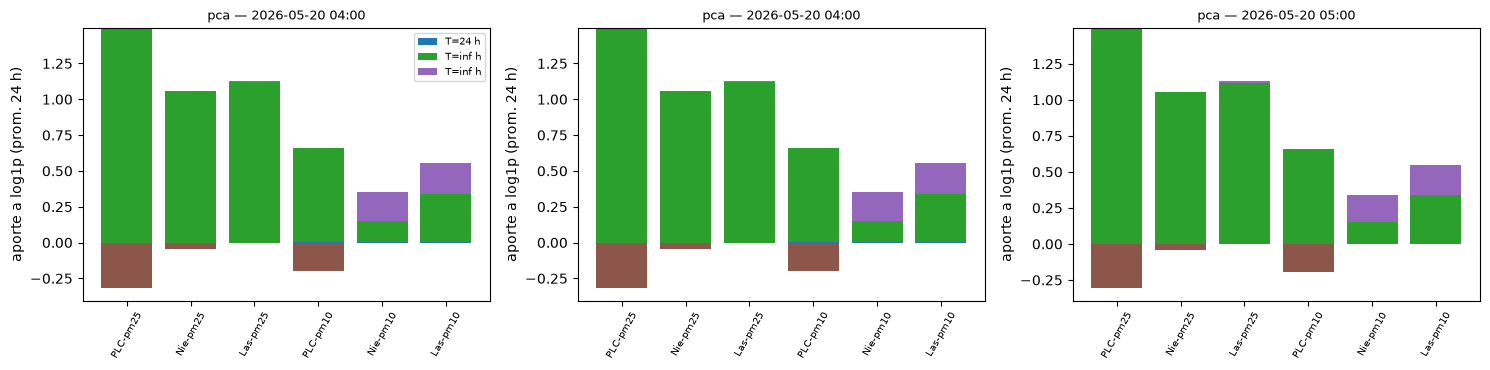

pca último episodio: pronóstico [71.7 39.1 55.7 58.4 37.4 54.1]


In [4]:
rows = rec.rows
episodios = []
for s, p in [("Padre Las Casas II", "pm25"), ("Nielol", "pm25"), ("Las Encinas", "pm10")]:
    g = rows[(rows.estacion == s) & (rows.pollutant == p)]
    episodios.append(pd.Timestamp(g.loc[g.y_true.idxmax(), "timestamp"]))
for key in ["gru-s0", "pca"]:
    lam, shape, J, Vk, Wk, est, op = formas[key]
    U = op.U if op.U is not None else np.eye(est.d)
    Jm = J.mean(axis=0)                                  # [6, d] promedio de 24 h
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, ts in zip(axes, episodios):
        pos = rec.grid.index.get_indexer(pd.DatetimeIndex([ts]).tz_convert(rec.grid.index.tz))
        z = est.at(pos)[0]
        b = Wk @ (U.T @ z)
        contrib = np.real(np.einsum("cd,dm->cm", Jm, U @ (Vk * (lam ** 24) * b)))
        contrib = contrib * np.where(np.abs(np.imag(lam)) > 1e-10, 2.0, 1.0)   # par conjugado
        bottom_p, bottom_n = np.zeros(6), np.zeros(6)
        for j in range(len(lam)):
            c = contrib[:, j]
            ax.bar(CANALES, np.where(c > 0, c, 0), bottom=bottom_p, label=f"T={M.periodo_h([lam[j]])[0]:.0f} h")
            ax.bar(CANALES, np.where(c < 0, c, 0), bottom=bottom_n)
            bottom_p += np.where(c > 0, c, 0); bottom_n += np.where(c < 0, c, 0)
        ax.set_title(f"{key} — {ts:%Y-%m-%d %H:%M}", fontsize=9); ax.tick_params(axis="x", rotation=60, labelsize=7)
        ax.set_ylabel("aporte a log1p (prom. 24 h)")
    axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
    fc, _ = R.pronostico(rec, est, op, args.config, pos)
    print(key, "último episodio: pronóstico", np.round(fc[0], 1))

## 4. Estabilidad entre semillas y bootstrap (criterio de interpretabilidad de §9)

gru — n modos: 5 | cumple: False


,modo,periodo_h,vida_media_h,s1,s2,presente_semillas,bootstrap_80,intervalos_solapan
0,0,24.168714,312.475497,True,True,True,True,False
1,1,480.430280,136.182282,False,False,False,False,False
2,2,inf,64.118614,False,True,False,False,True
3,3,inf,428.020315,False,False,False,False,True
4,4,3096.871303,142.733290,False,False,False,False,False


pca — n modos: 3 | cumple: False


,modo,periodo_h,vida_media_h,presente_semillas,bootstrap_80,intervalos_solapan
0,0,24.29066,875.716951,True,True,True
1,1,inf,486.631309,True,False,True
2,2,inf,281.243340,True,False,True


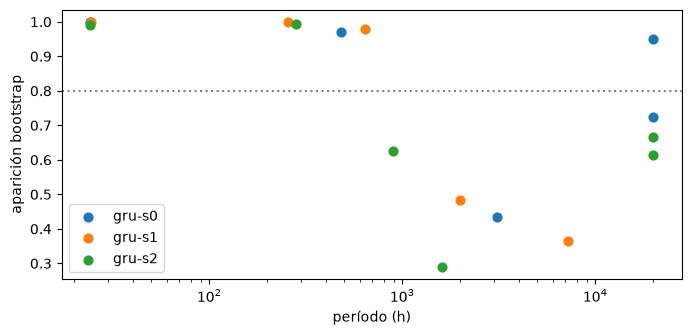

In [5]:
for rep, info in cierre["interpretabilidad"].items():
    print(rep, "— n modos:", info["n_modos"], "| cumple:", info["cumple"])
    display(pd.DataFrame(info["tabla"]))
fig, ax = plt.subplots(figsize=(8, 3.5))
for s in SEEDS:
    b = boot(f"gru-s{s}")
    ax.scatter(b["periodo_h"].replace(np.inf, 2e4), b["aparicion"], label=f"gru-s{s}", s=40)
ax.axhline(0.8, color="grey", ls=":"); ax.set_xscale("log"); ax.set_xlabel("período (h)"); ax.set_ylabel("aparición bootstrap")
ax.legend(); plt.show()

## 5. Matriz de forzamiento `K_ma`

No aplica: el rollout final es **autónomo** (1.3: la variante exógena no mejoró de forma significativa). `K_ma` de la variante exógena está en los runs `…-e13b-…` (`k_ma.parquet`).